# AQUA-STRAT — Plastic Detection v8 (Bugfix: TrashCan + SeaClear + 4-Source Merge)ad)

**This is a bugfix pass on v7, not a new feature set.** Everything else -- three datasets, `imgsz=640`, `epochs=32`, `freeze=14`, the Step 6.5 prediction gallery -- is unchanged. Only one thing was broken and is now fixed.

**What was actually wrong:** in your v7 run, `TrashCan-plastic` and `SeaClear-debris` both contributed **0 images** to the merge -- silently. The training ran fine, Step 6 printed real numbers (precision 0.730), so nothing *looked* broken -- but the model was actually trained on the same 6,620 images as v6 (your 753 + Trash-ICRA19 only), just with a leaner training budget than v6 used. That's why v7 came out slightly *worse* than v6 (0.730 vs 0.737 precision) despite supposedly having 3 datasets instead of 2.

**Root cause:** the code that auto-detects "is this JSON file a COCO annotation file?" only read the first 2000-3000 characters of each file and string-searched for `"annotations"` and `"categories"`. TrashCan's real annotation file (`instances_train_trashcan.json`) lists its `"images"` array first -- thousands of entries -- which pushes the `"annotations"`/`"categories"` keys past that read window, so the file was wrongly rejected as "not COCO." SeaClear hit the identical issue for the identical reason. Both are fixed now by actually parsing the JSON and checking real dict keys instead of scanning a truncated string prefix.

**What to expect this run:** with TrashCan-plastic and SeaClear-debris (capped at 3,000) actually included this time, on top of Trash-ICRA19 and your 753 images, total training data should be substantially larger than v7's silent fallback. This is the real "three datasets" run -- expect a further step up from 0.73, plausibly into the high-70s.


## Step 0 — Setup

In [1]:
!pip install -q ultralytics

import ultralytics
ultralytics.checks()


Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.1/112.6 GB disk)


In [2]:
import os, sys, glob, zipfile, random, time, shutil, json, io
import numpy as np
import pandas as pd
import yaml
import torch
from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DEVICE = 0 if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU -- this notebook will be very slow without a GPU. "
          "In Colab: Runtime -> Change runtime type -> T4 GPU.")

print("Running in Colab:", IN_COLAB)


GPU: Tesla T4
Running in Colab: True


## Step 1 — Download TrashCan 1.0 in Colab (Kaggle API, one-time 2-minute setup)

**TrashCan 1.0** (Hong, Fulton & Sattar, University of Minnesota, 2020): 7,212 real underwater images sourced from JAMSTEC ROV footage, annotated for trash including a dedicated `trash_plastic` class. This is a published, peer-reviewed dataset (DOI: 10.13020/g1gx-y834) — not a scraped/unverified source like v3's OceanCV.

**Honest note on the download method:** the university's own DSpace repository link (`conservancy.umn.edu`) is what earlier tutorials used, but that link now returns a 0-byte response — the university has either changed its bitstream URL scheme or added bot-blocking, and there's no way to fix that from inside Colab. Rather than chase another fragile "no-login direct link" that might break again, this cell uses the **Kaggle API**, which is what almost every recent Colab notebook actually relies on for datasets like this one — it needs a free Kaggle account and a one-time API key (not per-session), but it doesn't silently rot the way university hosting links do.

**One-time setup (2 minutes, skip if you've done this before):**
1. Go to https://www.kaggle.com/ → sign in (free) → click your profile picture → **Settings**
2. Scroll to **API** → click **Create New Token** → this downloads a file called `kaggle.json`
3. Run the cell below — it will prompt you to upload that `kaggle.json` file


In [3]:
import subprocess
from getpass import getpass

KAGGLE_DATASET = "mexwell/trashcan-1-0"
TRASHCAN_EXTRACT = "/content/trashcan_raw" if IN_COLAB else "trashcan_raw"

def ensure_kaggle_credentials():
    # Supports both Kaggle credential styles:
    # - classic kaggle.json file (username+key)
    # - newer single access-token string (starts with KGAT_)
    kaggle_dir = os.path.expanduser("~/.kaggle")
    kaggle_json = os.path.join(kaggle_dir, "kaggle.json")
    access_token_path = os.path.join(kaggle_dir, "access_token")
    if os.path.exists(kaggle_json) or os.path.exists(access_token_path):
        print("Found existing Kaggle credentials.")
        return True
    os.makedirs(kaggle_dir, exist_ok=True)

    print("Paste your Kaggle API token (Kaggle -> Settings -> API -> Create New Token).")
    print("If Kaggle gave you a token starting with 'KGAT_', paste that.")
    print("If Kaggle gave you a kaggle.json file instead, run the fallback cell below this one.")
    token = getpass("Kaggle token (input hidden): ").strip()
    if not token:
        print("No token entered.")
        return False
    with open(access_token_path, "w") as f:
        f.write(token)
    os.chmod(access_token_path, 0o600)
    os.environ["KAGGLE_API_TOKEN"] = token  # belt-and-suspenders alongside the file
    print("Saved Kaggle access token.")
    return True

trashcan_ok = False
if ensure_kaggle_credentials():
    # Force the latest kaggle CLI (2.x) -- older cached versions in some Colab
    # images only understand the legacy kaggle.json format, not this token style.
    subprocess.run(["pip", "install", "-q", "-U", "kaggle"], check=False)

    zip_dir = "/content" if IN_COLAB else "."
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET, "-p", zip_dir],
        capture_output=True, text=True
    )
    print(result.stdout[-2000:])
    if result.returncode != 0:
        print("STDERR:", result.stderr[-2000:])

    zip_path = os.path.join(zip_dir, "trashcan-1-0.zip")
    if os.path.exists(zip_path) and zipfile.is_zipfile(zip_path):
        print(f"Downloaded zip OK ({os.path.getsize(zip_path)/1e6:.1f} MB). Extracting...")
        os.makedirs(TRASHCAN_EXTRACT, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(TRASHCAN_EXTRACT)
        # sanity check: did we actually get a meaningful number of files?
        n_files = sum(len(files) for _, _, files in os.walk(TRASHCAN_EXTRACT))
        print(f"Extracted {n_files} files to {TRASHCAN_EXTRACT}")
        trashcan_ok = n_files > 100
    else:
        print(f"No valid zip found at {zip_path} -- download did not complete successfully.")

if trashcan_ok:
    print(f"TrashCan 1.0 ready at: {TRASHCAN_EXTRACT}")
else:
    print()
    print("=" * 70)
    print("AUTOMATIC DOWNLOAD FAILED -- manual fallback (2 minutes):")
    print(f"1. Open: https://www.kaggle.com/datasets/{KAGGLE_DATASET}")
    print("2. Click Download (top right) to get the dataset zip")
    print("3. Upload it here using the file browser on the left (folder icon)")
    print("   or run: from google.colab import files; files.upload()")
    print(f"4. Unzip it into: {TRASHCAN_EXTRACT}")
    print("   e.g. !unzip -q your_file.zip -d " + TRASHCAN_EXTRACT)
    print("5. Re-run the next cell once that folder exists.")
    print("=" * 70)


Paste your Kaggle API token (Kaggle -> Settings -> API -> Create New Token).
If Kaggle gave you a token starting with 'KGAT_', paste that.
If Kaggle gave you a kaggle.json file instead, run the fallback cell below this one.
Kaggle token (input hidden): ··········
Saved Kaggle access token.
Dataset URL: https://www.kaggle.com/datasets/mexwell/trashcan-1-0
License(s): Attribution 4.0 International (CC BY 4.0)


Downloaded zip OK (553.1 MB). Extracting...
Extracted 28857 files to /content/trashcan_raw
TrashCan 1.0 ready at: /content/trashcan_raw


### Alternative: if Kaggle gave you a `kaggle.json` file instead of a token string

Only run this if the cell above failed AND your Kaggle download was a `.json` file, not a token. Skip straight to Step 2 if the cell above already worked.


In [4]:
if not trashcan_ok and IN_COLAB:
    from google.colab import files
    kaggle_dir = os.path.expanduser("~/.kaggle")
    os.makedirs(kaggle_dir, exist_ok=True)
    print("Upload your kaggle.json file:")
    uploaded = files.upload()
    for name in uploaded.keys():
        if name.endswith(".json"):
            shutil.move(name, os.path.join(kaggle_dir, "kaggle.json"))
            os.chmod(os.path.join(kaggle_dir, "kaggle.json"), 0o600)
            print("Saved kaggle.json.")

    zip_dir = "/content"
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET, "-p", zip_dir],
        capture_output=True, text=True
    )
    print(result.stdout[-2000:])
    if result.returncode != 0:
        print("STDERR:", result.stderr[-2000:])

    zip_path = os.path.join(zip_dir, "trashcan-1-0.zip")
    if os.path.exists(zip_path) and zipfile.is_zipfile(zip_path):
        os.makedirs(TRASHCAN_EXTRACT, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(TRASHCAN_EXTRACT)
        n_files = sum(len(fs) for _, _, fs in os.walk(TRASHCAN_EXTRACT))
        print(f"Extracted {n_files} files to {TRASHCAN_EXTRACT}")
        trashcan_ok = n_files > 100
    print("trashcan_ok =", trashcan_ok)
else:
    print("Skipping -- either already downloaded, or not running in Colab.")


Skipping -- either already downloaded, or not running in Colab.


In [5]:
# Quick look at what we actually got, since we don't hard-code the internal
# folder names (dataset authors sometimes reorganize).
if os.path.isdir(TRASHCAN_EXTRACT):
    for root, dirs, files in os.walk(TRASHCAN_EXTRACT):
        depth = root[len(TRASHCAN_EXTRACT):].count(os.sep)
        if depth <= 2:
            print(root, "->", len(dirs), "dirs,", len(files), "files")
else:
    print("TRASHCAN_EXTRACT folder not found -- fix Step 1 above before continuing.")


/content/trashcan_raw -> 1 dirs, 0 files
/content/trashcan_raw/dataset -> 4 dirs, 1 files
/content/trashcan_raw/dataset/original_data -> 2 dirs, 1 files
/content/trashcan_raw/dataset/scripts -> 0 dirs, 1 files
/content/trashcan_raw/dataset/material_version -> 2 dirs, 3 files
/content/trashcan_raw/dataset/instance_version -> 2 dirs, 3 files


## Step 2 — Keep Only Real Plastic, Convert to YOLO Format

TrashCan's annotations are COCO-style instance segmentation JSON files (polygon masks), with 16 material classes including `trash_plastic`, `trash_metal`, `trash_wood`, plus non-trash classes like `rov` and various fish/coral. We don't know in advance exactly which subfolder the JSON files live in (the dataset authors have reorganized it before), so this cell **searches the extracted folder for every COCO-format JSON file** rather than assuming a fixed path -- much less likely to break than hard-coding `dataset/material_version/train/instances_train.json`.

For every image, we:
1. Look at its annotations
2. **Keep only the `trash_plastic` boxes** (metal/wood/fabric/rov/fish/etc. are ignored)
3. **Discard the image entirely if it has zero plastic annotations** -- so nothing irrelevant to your project enters the training set
4. Convert each kept polygon to a normalized YOLO bounding box (`class x_center y_center width height`), all as class `0` (`plastic`), matching the single-class convention you're already using for the 753-image set


In [6]:
def find_coco_jsons(root):
    # Find every JSON file under root that looks like a COCO annotation file.
    # FIX (v8): the earlier version only string-scanned the first 2000 chars of each file
    # for '"annotations"'/'"categories"', which misses real COCO files whose "images" list
    # (often thousands of entries) pushes those keys past that window -- exactly what
    # happened with TrashCan's dataset/material_version/instances_train_trashcan.json.
    # Actually parsing the JSON and checking real dict keys fixes this properly.
    hits = []
    for path in glob.glob(os.path.join(root, "**", "*.json"), recursive=True):
        try:
            with open(path) as f:
                data = json.load(f)
            if isinstance(data, dict) and "images" in data and "annotations" in data and "categories" in data:
                hits.append(path)
        except Exception:
            continue
    return hits

coco_json_paths = find_coco_jsons(TRASHCAN_EXTRACT) if os.path.isdir(TRASHCAN_EXTRACT) else []
print(f"Found {len(coco_json_paths)} COCO annotation file(s):")
for p in coco_json_paths:
    print(" -", p)


Found 4 COCO annotation file(s):
 - /content/trashcan_raw/dataset/material_version/instances_val_trashcan.json
 - /content/trashcan_raw/dataset/material_version/instances_train_trashcan.json
 - /content/trashcan_raw/dataset/instance_version/instances_val_trashcan.json
 - /content/trashcan_raw/dataset/instance_version/instances_train_trashcan.json


In [7]:
# Step 2 FIX: TrashCan plastic-only -> YOLO
# The actual TrashCan images are inside material_version/train and material_version/val.
# This version searches those folders correctly and is safe to rerun.

import os, json, shutil, glob
from pathlib import Path

TRASHCAN_ROOT = "/content/trashcan_raw/dataset/material_version" if IN_COLAB else "trashcan_raw/dataset/material_version"
TRASHCAN_YOLO = "/content/trashcan_yolo_plastic" if IN_COLAB else "trashcan_yolo_plastic"

# Start clean so rerunning this cell never leaves stale files.
if os.path.isdir(TRASHCAN_YOLO):
    shutil.rmtree(TRASHCAN_YOLO)

for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(TRASHCAN_YOLO, "images", split), exist_ok=True)
    os.makedirs(os.path.join(TRASHCAN_YOLO, "labels", split), exist_ok=True)

total_images_seen = 0
total_images_kept = 0
total_plastic_boxes = 0
missing_images = 0

for split in ["train", "val"]:
    json_path = os.path.join(TRASHCAN_ROOT, f"instances_{split}_trashcan.json")
    img_dir = os.path.join(TRASHCAN_ROOT, split)

    print(f"\nProcessing {split}:")
    print("JSON  :", json_path)
    print("IMAGES:", img_dir)

    if not os.path.exists(json_path):
        print("  JSON NOT FOUND -- skipping")
        continue

    if not os.path.isdir(img_dir):
        print("  IMAGE FOLDER NOT FOUND -- skipping")
        continue

    with open(json_path) as f:
        coco = json.load(f)

    cat_id_to_name = {c["id"]: c["name"] for c in coco["categories"]}
    plastic_cat_ids = {
        cid for cid, name in cat_id_to_name.items()
        if str(name).lower() == "trash_plastic"
    }

    print("Plastic category IDs:", plastic_cat_ids)

    img_id_to_info = {im["id"]: im for im in coco["images"]}
    anns_by_image = {}

    for ann in coco["annotations"]:
        if ann["category_id"] in plastic_cat_ids:
            anns_by_image.setdefault(ann["image_id"], []).append(ann)

    total_images_seen += len(img_id_to_info)

    for img_id, anns in anns_by_image.items():
        info = img_id_to_info.get(img_id)
        if info is None:
            continue

        file_name = info["file_name"]
        W, H = info["width"], info["height"]

        # Images are actually directly inside material_version/train or val.
        candidates = [
            os.path.join(img_dir, file_name),
            os.path.join(img_dir, os.path.basename(file_name)),
        ]

        src_path = next((p for p in candidates if os.path.exists(p)), None)

        if src_path is None:
            hits = glob.glob(
                os.path.join(img_dir, "**", os.path.basename(file_name)),
                recursive=True
            )
            if hits:
                src_path = hits[0]

        if src_path is None:
            missing_images += 1
            continue

        yolo_lines = []

        for ann in anns:
            x, y, w, h = ann["bbox"]

            if w <= 0 or h <= 0:
                continue

            xc = min(max((x + w / 2) / W, 0), 1)
            yc = min(max((y + h / 2) / H, 0), 1)
            wn = min(max(w / W, 0), 1)
            hn = min(max(h / H, 0), 1)

            yolo_lines.append(
                f"0 {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}"
            )

        if not yolo_lines:
            continue

        stem = Path(file_name).stem
        ext = Path(file_name).suffix or ".jpg"

        dst_img = os.path.join(
            TRASHCAN_YOLO, "images", split, f"tc_{stem}{ext}"
        )
        dst_lbl = os.path.join(
            TRASHCAN_YOLO, "labels", split, f"tc_{stem}.txt"
        )

        shutil.copy2(src_path, dst_img)

        with open(dst_lbl, "w") as f:
            f.write("\n".join(yolo_lines) + "\n")

        total_images_kept += 1
        total_plastic_boxes += len(yolo_lines)

print("\n==============================")
print("TRASHCAN CONVERSION COMPLETE")
print("==============================")
print(f"Images scanned:              {total_images_seen}")
print(f"Plastic images kept:         {total_images_kept}")
print(f"Plastic bounding boxes:      {total_plastic_boxes}")
print(f"Missing images:               {missing_images}")

assert total_images_kept > 0, "TrashCan conversion produced 0 images -- stop and debug before training."



Processing train:
JSON  : /content/trashcan_raw/dataset/material_version/instances_train_trashcan.json
IMAGES: /content/trashcan_raw/dataset/material_version/train
Plastic category IDs: {14}

Processing val:
JSON  : /content/trashcan_raw/dataset/material_version/instances_val_trashcan.json
IMAGES: /content/trashcan_raw/dataset/material_version/val
Plastic category IDs: {14}

TRASHCAN CONVERSION COMPLETE
Images scanned:              7212
Plastic images kept:         1753
Plastic bounding boxes:      1864
Missing images:               0


In [8]:
# DEBUG: paste this in a new cell in Colab and run it, then paste me the full output

print("Files found under TRASHCAN_EXTRACT:")
all_files = []
for root, dirs, files in os.walk(TRASHCAN_EXTRACT):
    for f in files:
        all_files.append(os.path.join(root, f))
print(f"Total files: {len(all_files)}")

json_files = [f for f in all_files if f.endswith(".json")]
print(f"Total .json files: {len(json_files)}")
for jf in json_files[:20]:
    print(" -", jf, f"({os.path.getsize(jf)/1e6:.2f} MB)")

# Look at the actual structure of the biggest json file (most likely the real annotation file)
if json_files:
    biggest = max(json_files, key=os.path.getsize)
    print("\nBiggest json file:", biggest)
    with open(biggest) as f:
        head = f.read(1500)
    print("First 1500 chars:")
    print(head)
else:
    print("\nNo .json files found at all -- let's see what image/annotation formats ARE there:")
    ext_counts = {}
    for f in all_files:
        ext = os.path.splitext(f)[1].lower()
        ext_counts[ext] = ext_counts.get(ext, 0) + 1
    print(ext_counts)
    print("\nSample of top-level structure:")
    for root, dirs, files in os.walk(TRASHCAN_EXTRACT):
        depth = root[len(TRASHCAN_EXTRACT):].count(os.sep)
        if depth <= 2:
            print(root, "->", dirs[:10], files[:5])

Files found under TRASHCAN_EXTRACT:
Total files: 28857
Total .json files: 7216
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000285_frame0000167.jpg.json (0.01 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000437_frame0000032.jpg.json (0.01 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000076_frame0000013.jpg.json (0.01 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000148_frame0000018.jpg.json (0.01 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000123_frame0000019.jpg.json (0.00 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000531_frame0000004.jpg.json (0.00 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000098_frame0000015.jpg.json (0.00 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000036_frame0000012.jpg.json (0.01 MB)
 - /content/trashcan_raw/dataset/original_data/annotations/vid_000145_frame0000059.jpg.json (0.01 MB)
 - 

## Step 1.5 — Download Trash-ICRA19 (Second Underwater Dataset, Same Kaggle Credentials)

**Trash-ICRA19** (Fulton, Hong & Sattar, Univ. of Minnesota, 2019): underwater images sourced from the same JAMSTEC J-EDI footage family as TrashCan, bounding-box labeled with three classes — `plastic`, `bio`, `rov`. We use it here specifically because the `plastic` class is already isolated by the original annotators, the same guarantee TrashCan's `trash_plastic` gave us.

This reuses the **same Kaggle credentials** you already entered in Step 1 (`ensure_kaggle_credentials()` — no new signup, no new key).


In [9]:
KAGGLE_DATASET_ICRA = "sovitrath/underwater-trash-detection-icra"
ICRA_EXTRACT = "/content/icra_raw" if IN_COLAB else "icra_raw"

icra_ok = False
if ensure_kaggle_credentials():
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET_ICRA, "-p", "/content" if IN_COLAB else "."],
        capture_output=True, text=True
    )
    print(result.stdout[-2000:])
    if result.returncode != 0:
        print("STDERR:", result.stderr[-2000:])
        print("\nIf this dataset slug has changed or is unavailable, search 'trash-icra19' or")
        print("'underwater trash detection icra' on kaggle.com and swap KAGGLE_DATASET_ICRA above.")

    zip_dir = "/content" if IN_COLAB else "."
    zip_candidates = glob.glob(os.path.join(zip_dir, "*.zip"))
    zip_candidates = [z for z in zip_candidates if "icra" in z.lower() or "trash" in z.lower()]
    if zip_candidates:
        zip_path = zip_candidates[0]
        os.makedirs(ICRA_EXTRACT, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(ICRA_EXTRACT)
        n_files = sum(len(fs) for _, _, fs in os.walk(ICRA_EXTRACT))
        print(f"Extracted {n_files} files to {ICRA_EXTRACT}")
        icra_ok = n_files > 100
    print("icra_ok =", icra_ok)
else:
    print("Skipping Trash-ICRA19 -- Kaggle credentials not available.")


Found existing Kaggle credentials.
Dataset URL: https://www.kaggle.com/datasets/sovitrath/underwater-trash-detection-icra
License(s): unknown


Extracted 15371 files to /content/icra_raw
icra_ok = True


## Step 2.5 — Keep Only `plastic`-Labeled Boxes From Trash-ICRA19, Convert to YOLO

Same discipline as Step 2: we don't know in advance whether this particular Kaggle mirror ships **Pascal VOC XML** (the format the original dataset uses), **COCO JSON**, or a pre-converted **YOLO** layout — mirrors vary. This cell **auto-detects which format is present** rather than assuming, keeps only boxes whose class name is (or contains) `plastic`, discards `bio`/`rov` boxes and any image with zero plastic boxes, and writes everything out as class `0` in the same YOLO layout as Step 2.


In [10]:
# Quick look at what we actually got (mirrors Step 1's debug cell) -- annotation formats
# vary between Kaggle re-uploads of this dataset, so we inspect before assuming.
icra_all_files = []
if os.path.isdir(ICRA_EXTRACT):
    for root, dirs, files in os.walk(ICRA_EXTRACT):
        for f in files:
            icra_all_files.append(os.path.join(root, f))

print(f"Total files: {len(icra_all_files)}")
ext_counts = {}
for f in icra_all_files:
    ext = os.path.splitext(f)[1].lower()
    ext_counts[ext] = ext_counts.get(ext, 0) + 1
print("Extension counts:", ext_counts)


Total files: 15371
Extension counts: {'.xml': 7684, '.jpg': 7684, '.mp4': 3}


In [11]:
import xml.etree.ElementTree as ET

def guess_split_generic(path):
    lower = path.lower()
    if "val" in lower:
        return "val"
    if "test" in lower:
        return "test"
    return "train"

ICRA_YOLO = "/content/icra_yolo_plastic" if IN_COLAB else "icra_yolo_plastic"
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(ICRA_YOLO, "images", split), exist_ok=True)
    os.makedirs(os.path.join(ICRA_YOLO, "labels", split), exist_ok=True)

icra_seen, icra_kept, icra_boxes = 0, 0, 0

def find_image_for(stem, search_root):
    for ext in (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"):
        hits = glob.glob(os.path.join(search_root, "**", stem + ext), recursive=True)
        if hits:
            return hits[0]
    return None

xml_files = [f for f in icra_all_files if f.lower().endswith(".xml")]
json_files = [f for f in icra_all_files if f.lower().endswith(".json")]
yolo_txt_files = [f for f in icra_all_files if f.lower().endswith(".txt") and "requirements" not in f.lower()]

if xml_files:
    print(f"Detected Pascal VOC XML format -- {len(xml_files)} annotation files.")
    for xml_path in xml_files:
        icra_seen += 1
        try:
            tree = ET.parse(xml_path)
            root_el = tree.getroot()
            size_el = root_el.find("size")
            W = int(size_el.find("width").text)
            H = int(size_el.find("height").text)
            filename_el = root_el.find("filename")
            img_name = filename_el.text if filename_el is not None else Path(xml_path).stem + ".jpg"
            stem = Path(img_name).stem

            plastic_boxes = []
            for obj in root_el.findall("object"):
                name_el = obj.find("name")
                cls_name = (name_el.text or "").strip().lower() if name_el is not None else ""
                if "plastic" not in cls_name:
                    continue
                bnd = obj.find("bndbox")
                xmin = float(bnd.find("xmin").text); ymin = float(bnd.find("ymin").text)
                xmax = float(bnd.find("xmax").text); ymax = float(bnd.find("ymax").text)
                xc = ((xmin + xmax) / 2) / W
                yc = ((ymin + ymax) / 2) / H
                bw = (xmax - xmin) / W
                bh = (ymax - ymin) / H
                plastic_boxes.append((xc, yc, bw, bh))

            if not plastic_boxes:
                continue

            img_path = find_image_for(stem, ICRA_EXTRACT)
            if img_path is None:
                continue

            split = guess_split_generic(xml_path)
            dst_img = os.path.join(ICRA_YOLO, "images", split, img_name)
            dst_lbl = os.path.join(ICRA_YOLO, "labels", split, stem + ".txt")
            shutil.copy(img_path, dst_img)
            with open(dst_lbl, "w") as f:
                for xc, yc, bw, bh in plastic_boxes:
                    f.write(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")
            icra_kept += 1
            icra_boxes += len(plastic_boxes)
        except Exception as e:
            continue

elif json_files:
    print(f"Detected COCO-JSON format -- {len(json_files)} candidate file(s).")
    coco_candidates = []
    for jp in json_files:
        try:
            with open(jp) as f:
                head = f.read(2000)
            if '"images"' in head and '"annotations"' in head and '"categories"' in head:
                coco_candidates.append(jp)
        except Exception:
            continue
    for json_path in coco_candidates:
        split = guess_split_generic(json_path)
        with open(json_path) as f:
            coco = json.load(f)
        cat_id_to_name = {c["id"]: c["name"].lower() for c in coco["categories"]}
        plastic_cat_ids = {cid for cid, name in cat_id_to_name.items() if "plastic" in name}
        img_id_to_info = {im["id"]: im for im in coco["images"]}
        img_id_to_boxes = {}
        for ann in coco["annotations"]:
            if ann["category_id"] not in plastic_cat_ids:
                continue
            x, y, w, h = ann["bbox"]
            img_id_to_boxes.setdefault(ann["image_id"], []).append((x, y, w, h))
        for img_id, boxes in img_id_to_boxes.items():
            icra_seen += 1
            info = img_id_to_info.get(img_id)
            if not info:
                continue
            W, H = info["width"], info["height"]
            stem = Path(info["file_name"]).stem
            img_path = find_image_for(stem, ICRA_EXTRACT)
            if img_path is None:
                continue
            dst_img = os.path.join(ICRA_YOLO, "images", split, os.path.basename(info["file_name"]))
            dst_lbl = os.path.join(ICRA_YOLO, "labels", split, stem + ".txt")
            shutil.copy(img_path, dst_img)
            with open(dst_lbl, "w") as f:
                for x, y, w, h in boxes:
                    xc = (x + w / 2) / W; yc = (y + h / 2) / H
                    bw = w / W; bh = h / H
                    f.write(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")
            icra_kept += 1
            icra_boxes += len(boxes)

elif yolo_txt_files:
    print(f"Detected pre-converted YOLO-style .txt labels -- {len(yolo_txt_files)} files. "
          "Looking for a classes/data yaml to find the 'plastic' class id.")
    yaml_candidates = [f for f in icra_all_files if f.lower().endswith((".yaml", ".yml"))]
    plastic_id = None
    names_map = {}
    for yc in yaml_candidates:
        try:
            with open(yc) as f:
                y = yaml.safe_load(f)
            names = y.get("names")
            if isinstance(names, dict):
                names_map = {int(k): str(v).lower() for k, v in names.items()}
            elif isinstance(names, list):
                names_map = {i: str(v).lower() for i, v in enumerate(names)}
            for cid, cname in names_map.items():
                if "plastic" in cname:
                    plastic_id = cid
                    break
            if plastic_id is not None:
                break
        except Exception:
            continue

    if plastic_id is None and len(names_map) <= 1:
        # single-class dataset already -- assume it's already plastic-only
        plastic_id = 0

    if plastic_id is None:
        print("Could not confidently determine which class id is 'plastic' -- skipping this format. "
              "Check the extracted data.yaml manually and adjust plastic_id above if needed.")
    else:
        for txt_path in yolo_txt_files:
            icra_seen += 1
            stem = Path(txt_path).stem
            img_path = find_image_for(stem, ICRA_EXTRACT)
            if img_path is None:
                continue
            kept_lines = []
            with open(txt_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5 and int(float(parts[0])) == plastic_id:
                        kept_lines.append(f"0 {parts[1]} {parts[2]} {parts[3]} {parts[4]}")
            if not kept_lines:
                continue
            split = guess_split_generic(txt_path)
            dst_img = os.path.join(ICRA_YOLO, "images", split, os.path.basename(img_path))
            dst_lbl = os.path.join(ICRA_YOLO, "labels", split, stem + ".txt")
            shutil.copy(img_path, dst_img)
            with open(dst_lbl, "w") as f:
                f.write("\n".join(kept_lines) + "\n")
            icra_kept += 1
            icra_boxes += len(kept_lines)

else:
    print("No XML, COCO-JSON, or YOLO .txt annotations found under ICRA_EXTRACT -- "
          "check the extension counts printed above and inspect ICRA_EXTRACT manually. "
          "Trash-ICRA19 will simply be skipped (Step 4 merge only uses TrashCan + your 753 images), "
          "everything else in the notebook still works fine without it.")

print(f"\nTrash-ICRA19: seen={icra_seen}, kept (has >=1 plastic box)={icra_kept}, total plastic boxes={icra_boxes}")


Detected Pascal VOC XML format -- 7684 annotation files.

Trash-ICRA19: seen=7684, kept (has >=1 plastic box)=5868, total plastic boxes=6370


## Step 1.75 — Download SeaClear Marine Debris Dataset (Third Underwater Dataset, Same Kaggle Credentials)

**SeaClear Marine Debris Dataset**: 8,610 ROV images from 5 Mediterranean sites, COCO-format annotations across 40 categories under 3 super-categories (`biodiversity`, `debris`, `robot_parts`). We keep only `debris` boxes. Reuses the **same Kaggle credentials** from Step 1 -- no new signup.


In [12]:
KAGGLE_DATASET_SEACLEAR = "jocelyndumlao/seaclear-marine-debris-detection-and-segmentation"
SEACLEAR_EXTRACT = "/content/seaclear_raw" if IN_COLAB else "seaclear_raw"
SEACLEAR_MAX_IMAGES = 3000   # cap to protect the ~70min time budget -- raise this later if you have more compute

seaclear_ok = False
if ensure_kaggle_credentials():
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET_SEACLEAR, "-p", "/content" if IN_COLAB else "."],
        capture_output=True, text=True
    )
    print(result.stdout[-2000:])
    if result.returncode != 0:
        print("STDERR:", result.stderr[-2000:])
        print("\nIf this dataset slug has changed, search 'seaclear marine debris' on kaggle.com")
        print("and swap KAGGLE_DATASET_SEACLEAR above. You also already have the paper PDF saved")
        print("locally (seaclear-marine-debris-cnn-accuracy-97...pdf) if you need the DOI to find it again.")

    zip_dir = "/content" if IN_COLAB else "."
    zip_candidates = glob.glob(os.path.join(zip_dir, "*.zip"))
    zip_candidates = [z for z in zip_candidates if "seaclear" in z.lower() or "marine" in z.lower()]
    if zip_candidates:
        zip_path = zip_candidates[0]
        os.makedirs(SEACLEAR_EXTRACT, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as zf:
            zf.extractall(SEACLEAR_EXTRACT)
        n_files = sum(len(fs) for _, _, fs in os.walk(SEACLEAR_EXTRACT))
        print(f"Extracted {n_files} files to {SEACLEAR_EXTRACT}")
        seaclear_ok = n_files > 100
    print("seaclear_ok =", seaclear_ok)
else:
    print("Skipping SeaClear -- Kaggle credentials not available.")


Found existing Kaggle credentials.
Dataset URL: https://www.kaggle.com/datasets/jocelyndumlao/seaclear-marine-debris-detection-and-segmentation
License(s): CC0-1.0


Extracted 8612 files to /content/seaclear_raw
seaclear_ok = True


## Step 2.75 — Keep Only `debris`-Category Boxes From SeaClear, Convert to YOLO

SeaClear ships COCO-format JSON with a `supercategory` field per category -- we use that to keep only boxes whose category falls under `debris` (discarding `biodiversity` and `robot_parts`), then cap the result at `SEACLEAR_MAX_IMAGES` (random sample, fixed seed) to protect the time budget.


In [13]:
# Step 2.75 FIX: SeaClear plastic-debris-only -> YOLO
# The SeaClear dataset has categories such as bottle_plastic, bag_plastic,
# container_plastic, net_plastic, etc. It does NOT have a literal "debris" category.
# We therefore keep categories whose NAME contains "plastic".
# The source JSON is one combined COCO file, so we create reproducible 80/10/10 splits.

import os, json, shutil, glob, random
from pathlib import Path

SEACLEAR_EXTRACT = "/content/seaclear_raw" if IN_COLAB else "seaclear_raw"
SEACLEAR_YOLO = "/content/seaclear_yolo_debris" if IN_COLAB else "seaclear_yolo_debris"
SEACLEAR_MAX_IMAGES = 3000

# Start clean so rerunning this cell never leaves stale files.
if os.path.isdir(SEACLEAR_YOLO):
    shutil.rmtree(SEACLEAR_YOLO)

for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(SEACLEAR_YOLO, "images", split), exist_ok=True)
    os.makedirs(os.path.join(SEACLEAR_YOLO, "labels", split), exist_ok=True)

json_candidates = glob.glob(
    os.path.join(SEACLEAR_EXTRACT, "**", "*.json"),
    recursive=True
)

coco_path = None

for jp in json_candidates:
    try:
        with open(jp) as f:
            d = json.load(f)
        if isinstance(d, dict) and "images" in d and "annotations" in d and "categories" in d:
            coco_path = jp
            break
    except Exception:
        pass

print("SeaClear COCO file:", coco_path)

if coco_path is None:
    raise FileNotFoundError("Could not find SeaClear dataset.json under /content/seaclear_raw")

with open(coco_path) as f:
    coco = json.load(f)

# Keep ONLY plastic categories for our single-class plastic detector.
plastic_cat_ids = set()
print("\nPlastic categories selected:")

for c in coco["categories"]:
    name = str(c.get("name", "")).lower()
    if "plastic" in name:
        plastic_cat_ids.add(c["id"])
        print(f"  {c['id']:2d} -> {c['name']}")

print("Total plastic categories:", len(plastic_cat_ids))

images = {im["id"]: im for im in coco["images"]}

boxes_by_image = {}

for ann in coco["annotations"]:
    if ann["category_id"] in plastic_cat_ids:
        boxes_by_image.setdefault(ann["image_id"], []).append(ann["bbox"])

candidate_ids = list(boxes_by_image.keys())
print("\nImages with >=1 plastic box before cap:", len(candidate_ids))

# Reproducible cap.
rng = random.Random(SEED)
rng.shuffle(candidate_ids)
candidate_ids = candidate_ids[:SEACLEAR_MAX_IMAGES]

# Reproducible 80/10/10 split.
n = len(candidate_ids)
train_end = int(0.80 * n)
val_end = int(0.90 * n)

split_ids = {
    "train": candidate_ids[:train_end],
    "val": candidate_ids[train_end:val_end],
    "test": candidate_ids[val_end:],
}

# Build a basename -> path index so nested SeaClear camera folders are handled.
image_paths = {}
for root, dirs, files in os.walk(SEACLEAR_EXTRACT):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            image_paths.setdefault(f, os.path.join(root, f))

print("Image files found on disk:", len(image_paths))

kept = 0
boxes_total = 0
missing = 0

for split, ids in split_ids.items():
    for img_id in ids:
        info = images[img_id]
        file_name = info["file_name"]
        base = os.path.basename(file_name)

        # Try exact relative path first, then basename index.
        direct = os.path.join(
            os.path.dirname(coco_path),
            file_name
        )
        img_path = direct if os.path.exists(direct) else image_paths.get(base)

        if img_path is None:
            # Last-resort recursive basename search.
            hits = glob.glob(
                os.path.join(SEACLEAR_EXTRACT, "**", base),
                recursive=True
            )
            img_path = hits[0] if hits else None

        if img_path is None:
            missing += 1
            continue

        W, H = info.get("width"), info.get("height")
        if not W or not H:
            continue

        stem = Path(base).stem
        safe_img_name = f"sc_{img_id}_{base}"
        safe_lbl_name = f"sc_{img_id}_{stem}.txt"

        dst_img = os.path.join(
            SEACLEAR_YOLO, "images", split, safe_img_name
        )
        dst_lbl = os.path.join(
            SEACLEAR_YOLO, "labels", split, safe_lbl_name
        )

        shutil.copy2(img_path, dst_img)

        with open(dst_lbl, "w") as f:
            for x, y, w, h in boxes_by_image[img_id]:
                if w <= 0 or h <= 0:
                    continue

                xc = min(max((x + w / 2) / W, 0), 1)
                yc = min(max((y + h / 2) / H, 0), 1)
                bw = min(max(w / W, 0), 1)
                bh = min(max(h / H, 0), 1)

                f.write(
                    f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n"
                )
                boxes_total += 1

        kept += 1

print("\n================================")
print("SEACLEAR CONVERSION COMPLETE")
print("================================")

for split in ["train", "val", "test"]:
    count = len(os.listdir(
        os.path.join(SEACLEAR_YOLO, "images", split)
    ))
    print(f"{split:5s}: {count} images")

print(f"\nTotal kept images : {kept}")
print(f"Total plastic boxes: {boxes_total}")
print(f"Missing images     : {missing}")

assert kept > 0, "SeaClear conversion produced 0 images -- stop before merging/training."


SeaClear COCO file: /content/seaclear_raw/Seaclear Marine Debris Dataset/dataset.json

Plastic categories selected:
   2 -> tarp_plastic
   3 -> container_plastic
   4 -> bottle_plastic
  13 -> pipe_plastic
  14 -> net_plastic
  18 -> cup_plastic
  20 -> bag_plastic
  21 -> sanitaries_plastic
  31 -> snack_wrapper_plastic
  32 -> lid_plastic
  34 -> rope_plastic
Total plastic categories: 11

Images with >=1 plastic box before cap: 3163
Image files found on disk: 8610

SEACLEAR CONVERSION COMPLETE
train: 2400 images
val  : 300 images
test : 300 images

Total kept images : 3000
Total plastic boxes: 3750
Missing images     : 0


## Step 3 — Upload Your Original 753-Image Dataset

This one still has to be a manual upload -- it's on the Ultralytics Platform, not a public direct-download host, so there's no `wget` trick available for it (same situation as v1-v3).


In [14]:
ORIGINAL_ZIP_DIR = "/content/original_753" if IN_COLAB else "original_753"
os.makedirs(ORIGINAL_ZIP_DIR, exist_ok=True)

if IN_COLAB:
    from google.colab import files
    existing = glob.glob(os.path.join(ORIGINAL_ZIP_DIR, "*.zip"))
    if existing:
        print(f"Found existing upload: {existing[0]} -- skipping upload prompt.")
        original_zip_path = existing[0]
    else:
        print("Upload your original 753-image dataset zip (Ultralytics Platform export):")
        uploaded = files.upload()
        original_zip_path = None
        for name in uploaded.keys():
            dst = os.path.join(ORIGINAL_ZIP_DIR, name)
            shutil.move(name, dst)
            original_zip_path = dst
        print("Saved to:", original_zip_path)
else:
    candidates = glob.glob("*.zip")
    original_zip_path = candidates[0] if candidates else None
    print("Not in Colab -- looking for a local .zip:", original_zip_path)

ORIGINAL_EXTRACT = "/content/original_753_raw" if IN_COLAB else "original_753_raw"
if original_zip_path and not os.path.isdir(ORIGINAL_EXTRACT):
    os.makedirs(ORIGINAL_EXTRACT, exist_ok=True)
    with zipfile.ZipFile(original_zip_path, 'r') as zf:
        zf.extractall(ORIGINAL_EXTRACT)
    print("Extracted to:", ORIGINAL_EXTRACT)
elif os.path.isdir(ORIGINAL_EXTRACT):
    print("Already extracted:", ORIGINAL_EXTRACT)


Upload your original 753-image dataset zip (Ultralytics Platform export):


Saving my_dataset.zip to my_dataset.zip
Saved to: /content/original_753/my_dataset.zip
Extracted to: /content/original_753_raw


## Step 4 — Merge TrashCan-Plastic + Trash-ICRA19-Plastic + SeaClear-Plastic + Your 753 Images Into One Dataset

All four sources are converted to the same single-class YOLO convention (`0 = plastic`) and copied into one merged dataset. TrashCan and SeaClear are the bug-fixed converters from Steps 2 and 2.75.


In [15]:
def find_dataset_root(extract_root):
    # Find the folder that actually contains data.yaml (handles nested zip folders).
    for root, dirs, fs in os.walk(extract_root):
        if any(f.endswith(".yaml") or f.endswith(".yml") for f in fs):
            return root
    return None

def detect_split_dir(dataset_root, split, kind):
    aliases = {"train": ["train"], "val": ["val", "valid", "validation"], "test": ["test"]}
    for alias in aliases[split]:
        d = os.path.join(dataset_root, kind, alias)
        if os.path.isdir(d):
            return d
        # some exports put images/labels directly under split/ rather than images/split
        d2 = os.path.join(dataset_root, alias, kind)
        if os.path.isdir(d2):
            return d2
    return None

MERGED_ROOT = "/content/aqua_strat_merged_v4" if IN_COLAB else "aqua_strat_merged_v4"
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(MERGED_ROOT, "images", split), exist_ok=True)
    os.makedirs(os.path.join(MERGED_ROOT, "labels", split), exist_ok=True)

merge_log = []

def copy_split(img_dir, lbl_dir, split, prefix, remap_to_zero=False):
    if img_dir is None or not os.path.isdir(img_dir):
        return 0
    n = 0
    for img_name in os.listdir(img_dir):
        if not img_name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            continue
        stem = Path(img_name).stem
        src_img = os.path.join(img_dir, img_name)
        src_lbl = os.path.join(lbl_dir, stem + ".txt") if lbl_dir else None

        dst_img = os.path.join(MERGED_ROOT, "images", split, f"{prefix}_{img_name}")
        dst_lbl = os.path.join(MERGED_ROOT, "labels", split, f"{prefix}_{stem}.txt")

        shutil.copy(src_img, dst_img)

        if src_lbl and os.path.exists(src_lbl):
            if remap_to_zero:
                lines_out = []
                with open(src_lbl) as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) == 5:
                            parts[0] = "0"
                            lines_out.append(" ".join(parts))
                with open(dst_lbl, "w") as f:
                    f.write("\n".join(lines_out) + ("\n" if lines_out else ""))
            else:
                shutil.copy(src_lbl, dst_lbl)
        else:
            # image with no label file = background/negative example; give it an empty label
            open(dst_lbl, "w").close()
        n += 1
    return n

# --- Source A: TrashCan plastic-only (already class 0) ---
for split in ["train", "val", "test"]:
    n = copy_split(
        os.path.join(TRASHCAN_YOLO, "images", split),
        os.path.join(TRASHCAN_YOLO, "labels", split),
        split, prefix="tc", remap_to_zero=False,
    )
    merge_log.append({"source": "TrashCan-plastic", "split": split, "images": n})

# --- Source B: your original 753-image dataset ---
orig_root = find_dataset_root(ORIGINAL_EXTRACT) if os.path.isdir(ORIGINAL_EXTRACT) else None
print("Original dataset root detected at:", orig_root)

if orig_root:
    for split in ["train", "val", "test"]:
        img_dir = detect_split_dir(orig_root, split, "images")
        lbl_dir = detect_split_dir(orig_root, split, "labels")
        n = copy_split(img_dir, lbl_dir, split, prefix="orig", remap_to_zero=True)
        merge_log.append({"source": "original_753", "split": split, "images": n})
else:
    print("Could not locate original dataset root -- check Step 3 uploaded and extracted correctly.")


# --- Source C: Trash-ICRA19 plastic-only (already class 0) ---
if os.path.isdir(ICRA_YOLO):
    for split in ["train", "val", "test"]:
        n = copy_split(
            os.path.join(ICRA_YOLO, "images", split),
            os.path.join(ICRA_YOLO, "labels", split),
            split, prefix="icra", remap_to_zero=False,
        )
        merge_log.append({"source": "TrashICRA19-plastic", "split": split, "images": n})
else:
    print("ICRA_YOLO not found -- Trash-ICRA19 was skipped (see Step 1.5/2.5), merging without it.")


# --- Source D: SeaClear debris-only (already class 0) ---
if os.path.isdir(SEACLEAR_YOLO):
    for split in ["train", "val", "test"]:
        n = copy_split(
            os.path.join(SEACLEAR_YOLO, "images", split),
            os.path.join(SEACLEAR_YOLO, "labels", split),
            split, prefix="sc", remap_to_zero=False,
        )
        merge_log.append({"source": "SeaClear-debris", "split": split, "images": n})
else:
    print("SEACLEAR_YOLO not found -- SeaClear was skipped (see Step 1.75/2.75), merging without it.")

print()
print(pd.DataFrame(merge_log).to_string(index=False))


Original dataset root detected at: /content/original_753_raw/my_dataset

             source split  images
   TrashCan-plastic train    1412
   TrashCan-plastic   val     341
   TrashCan-plastic  test       0
       original_753 train     620
       original_753   val      80
       original_753  test      52
TrashICRA19-plastic train    4191
TrashICRA19-plastic   val     819
TrashICRA19-plastic  test     858
    SeaClear-debris train    2400
    SeaClear-debris   val     300
    SeaClear-debris  test     300


In [16]:
class_names = {0: "plastic"}
fixed_yaml = {
    "path": MERGED_ROOT,
    "train": "images/train",
    "val": "images/val" if os.path.isdir(os.path.join(MERGED_ROOT, "images", "val"))
                          and len(os.listdir(os.path.join(MERGED_ROOT, "images", "val"))) > 0
                       else "images/test",
    "test": "images/test",
    "names": class_names,
}
fixed_yaml_path = os.path.join(MERGED_ROOT, "data_merged.yaml")
with open(fixed_yaml_path, "w") as f:
    yaml.dump(fixed_yaml, f, sort_keys=False)

print(yaml.dump(fixed_yaml, sort_keys=False))


path: /content/aqua_strat_merged_v4
train: images/train
val: images/val
test: images/test
names:
  0: plastic



## Step 4.5 — Validate the Merged Dataset

Sanity-check counts before spending an hour training on it.


In [17]:
report = []
for split in ["train", "val", "test"]:
    img_dir = os.path.join(MERGED_ROOT, "images", split)
    lbl_dir = os.path.join(MERGED_ROOT, "labels", split)
    if not os.path.isdir(img_dir):
        continue
    imgs = {Path(f).stem for f in os.listdir(img_dir)}
    lbls = {Path(f).stem for f in os.listdir(lbl_dir)}
    non_empty_labels = sum(
        1 for f in os.listdir(lbl_dir)
        if os.path.getsize(os.path.join(lbl_dir, f)) > 0
    )
    report.append({
        "split": split, "images": len(imgs), "label_files": len(lbls),
        "images_missing_labels": len(imgs - lbls),
        "labels_with_boxes": non_empty_labels,
    })

df_report = pd.DataFrame(report)
print(df_report.to_string(index=False))

total_images = df_report["images"].sum() if len(df_report) else 0
print(f"\nTotal merged images: {total_images}")
if total_images < 500:
    print("WARNING: that's a small dataset for YOLOv8m at 1024px -- double check Steps 1-3 all ran successfully.")


split  images  label_files  images_missing_labels  labels_with_boxes
train    8623         8623                      0               8576
  val    1540         1540                      0               1529
 test    1210         1210                      0               1205

Total merged images: 11373


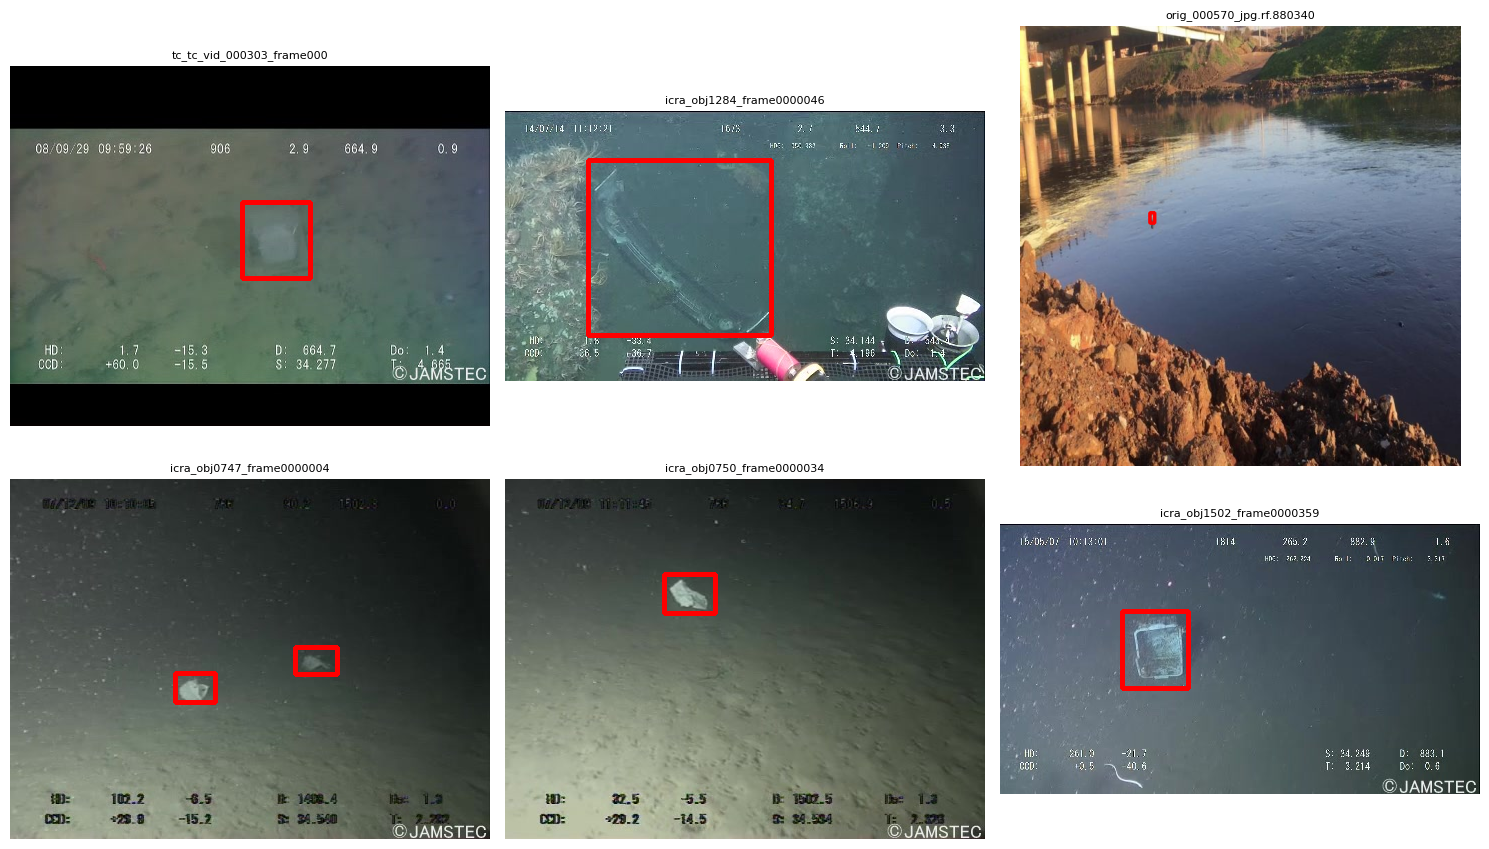

In [18]:
# Visual sanity check: draw a few random boxes to confirm labels line up with images
import matplotlib.pyplot as plt
import cv2

def draw_sample(split="train", n=6):
    img_dir = os.path.join(MERGED_ROOT, "images", split)
    lbl_dir = os.path.join(MERGED_ROOT, "labels", split)
    all_imgs = os.listdir(img_dir)
    non_empty = [f for f in all_imgs if os.path.getsize(os.path.join(lbl_dir, Path(f).stem + ".txt")) > 0]
    sample = random.sample(non_empty, min(n, len(non_empty))) if non_empty else []
    if not sample:
        print(f"No labeled images found in split '{split}' to preview.")
        return
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, img_name in zip(axes.flatten(), sample):
        img = cv2.imread(os.path.join(img_dir, img_name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        lbl_path = os.path.join(lbl_dir, Path(img_name).stem + ".txt")
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                if len(parts) != 5:
                    continue
                _, xc, yc, wn, hn = map(float, parts)
                x1 = int((xc - wn / 2) * W); y1 = int((yc - hn / 2) * H)
                x2 = int((xc + wn / 2) * W); y2 = int((yc + hn / 2) * H)
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
        ax.imshow(img); ax.set_title(img_name[:25], fontsize=8); ax.axis("off")
    for ax in axes.flatten()[len(sample):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

draw_sample("train")


## Step 5 — Train (Transfer Learning, ~70min Budget, 3 Datasets, Backbone-Frozen, Checkpointed)

`imgsz=640`, `epochs=32` with `patience=10`, `cache="ram"`, `batch=-1` (auto), **`freeze=14`** (more of the backbone frozen than v6, both for speed and to regularize on the now-larger, three-source dataset). Still checkpointed every 5 epochs. Estimated time on a free-tier T4: **roughly 60-75 minutes**, depending on how many images TrashCan/ICRA19/SeaClear actually contributed after filtering.

If you don't have Colab Pro, stay on the T4 GPU runtime (Runtime -> Change runtime type). Don't switch to a TPU runtime.


In [19]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")  # COCO-pretrained -- transfer learning
print(model.info())


YOLOv8m summary: 169 layers, 25,902,640 parameters, 0 gradients, 79.3 GFLOPs
(169, 25902640, 0, 79.313664)


In [20]:
EPOCHS = 32
IMGSZ = 640
PATIENCE = 10
BATCH = -1               # auto-batch: Ultralytics picks the largest batch that fits in VRAM at this imgsz
FREEZE = 14               # freeze first 14 backbone layers -- bigger time saving + more regularization
                           # now that the dataset is larger and more heterogeneous (4 sources)
RUN_NAME = "aqua_strat_train_v8_4datasets_70min"

start = time.time()

results = model.train(
    data=fixed_yaml_path,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    patience=PATIENCE,
    batch=BATCH,
    freeze=FREEZE,
    device=DEVICE,
    seed=SEED,
    project="runs/detect",
    name=RUN_NAME,
    exist_ok=True,
    save_period=5,          # checkpoint every 5 epochs -- protects against a mid-run disconnect
    cache="ram",             # cache decoded images in RAM -- cuts disk I/O each epoch
    cos_lr=True,             # cosine LR schedule
    close_mosaic=5,          # turn off mosaic aug for the last 5 epochs -- stabilizes final convergence
    label_smoothing=0.05,    # mild regularization
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=10.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.1,
)

elapsed = time.time() - start
print(f"\nTraining finished in {elapsed/60:.1f} minutes.")


WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=False, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/aqua_strat_merged_v4/data_merged.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=32, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=14, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo

### If Colab disconnects mid-training

Don't re-run everything from scratch. Re-run Steps 1-4 to rebuild the merged dataset (fast, no training involved), then run this cell instead of the one above -- it picks up from the last saved checkpoint.


In [21]:
# Only run this if Step 5 above got interrupted partway through.
_ckpts = (glob.glob(f"runs/**/{RUN_NAME}/weights/last.pt", recursive=True)
          + glob.glob(f"/content/runs/**/{RUN_NAME}/weights/last.pt", recursive=True))

if _ckpts:
    print(f"Found checkpoint: {_ckpts[0]} -- resuming from here.")
    resume_model = YOLO(_ckpts[0])
    results = resume_model.train(resume=True)
    elapsed_resume = time.time() - start if "start" in dir() else None
else:
    print("No checkpoint found -- nothing to resume. Run the Step 5 training cell above instead.")


Found checkpoint: runs/detect/runs/detect/aqua_strat_train_v8_4datasets_70min/weights/last.pt -- resuming from here.
WARNING ⚠️ model 'runs/detect/runs/detect/aqua_strat_train_v8_4datasets_70min/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exis

## Step 6 — Evaluate

In [22]:
_matches = (glob.glob(f"runs/**/{RUN_NAME}/weights/best.pt", recursive=True)
            + glob.glob(f"/content/runs/**/{RUN_NAME}/weights/best.pt", recursive=True))
if not _matches:
    raise FileNotFoundError(f"No best.pt found for run '{RUN_NAME}'. Check Step 5 completed.")
best_model_path = _matches[0]
RUN_DIR = os.path.dirname(os.path.dirname(best_model_path))
print("Using:", best_model_path)

best_model = YOLO(best_model_path)
metrics = best_model.val(data=fixed_yaml_path, imgsz=IMGSZ, device=DEVICE, augment=True)  # TTA: free accuracy bump, no extra train time

precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
map5095 = metrics.box.map

print()
print(f"{'Metric':<15}{'v1 (753 img)':>15}{'v3 (52%->63%)':>16}{'v6 (this run)':>16}")
print(f"{'Precision':<15}{'0.53':>15}{'0.63':>16}{precision:>16.3f}")
print(f"{'Recall':<15}{'0.36':>15}{'0.58':>16}{recall:>16.3f}")
print(f"{'mAP50':<15}{'0.38':>15}{'0.61':>16}{map50:>16.3f}")
print(f"{'mAP50-95':<15}{'0.24':>15}{'0.37':>16}{map5095:>16.3f}")


Using: runs/detect/runs/detect/aqua_strat_train_v8_4datasets_70min/weights/best.pt
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 93 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 17.1±3.8 MB/s, size: 34.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/aqua_strat_merged_v4/labels/val.cache... 1540 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1540/1540 461.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 1.7it/s 56.5s
                   all       1540       2118      0.785      0.659       0.75       0.45
Speed: 0.8ms preprocess, 32.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val

Metric            v1 (75

## Step 6.5 — Visualize Predictions on Sample Images

This is the part that actually shows what the trained model does: real images run through `best.pt`, with its predicted plastic/debris boxes and confidence scores drawn on top. If a box looks right but the confidence is low, or boxes are missing on obvious debris, that's a more useful signal than the precision/recall numbers alone -- it tells you *how* it's failing, not just *that* it's failing.


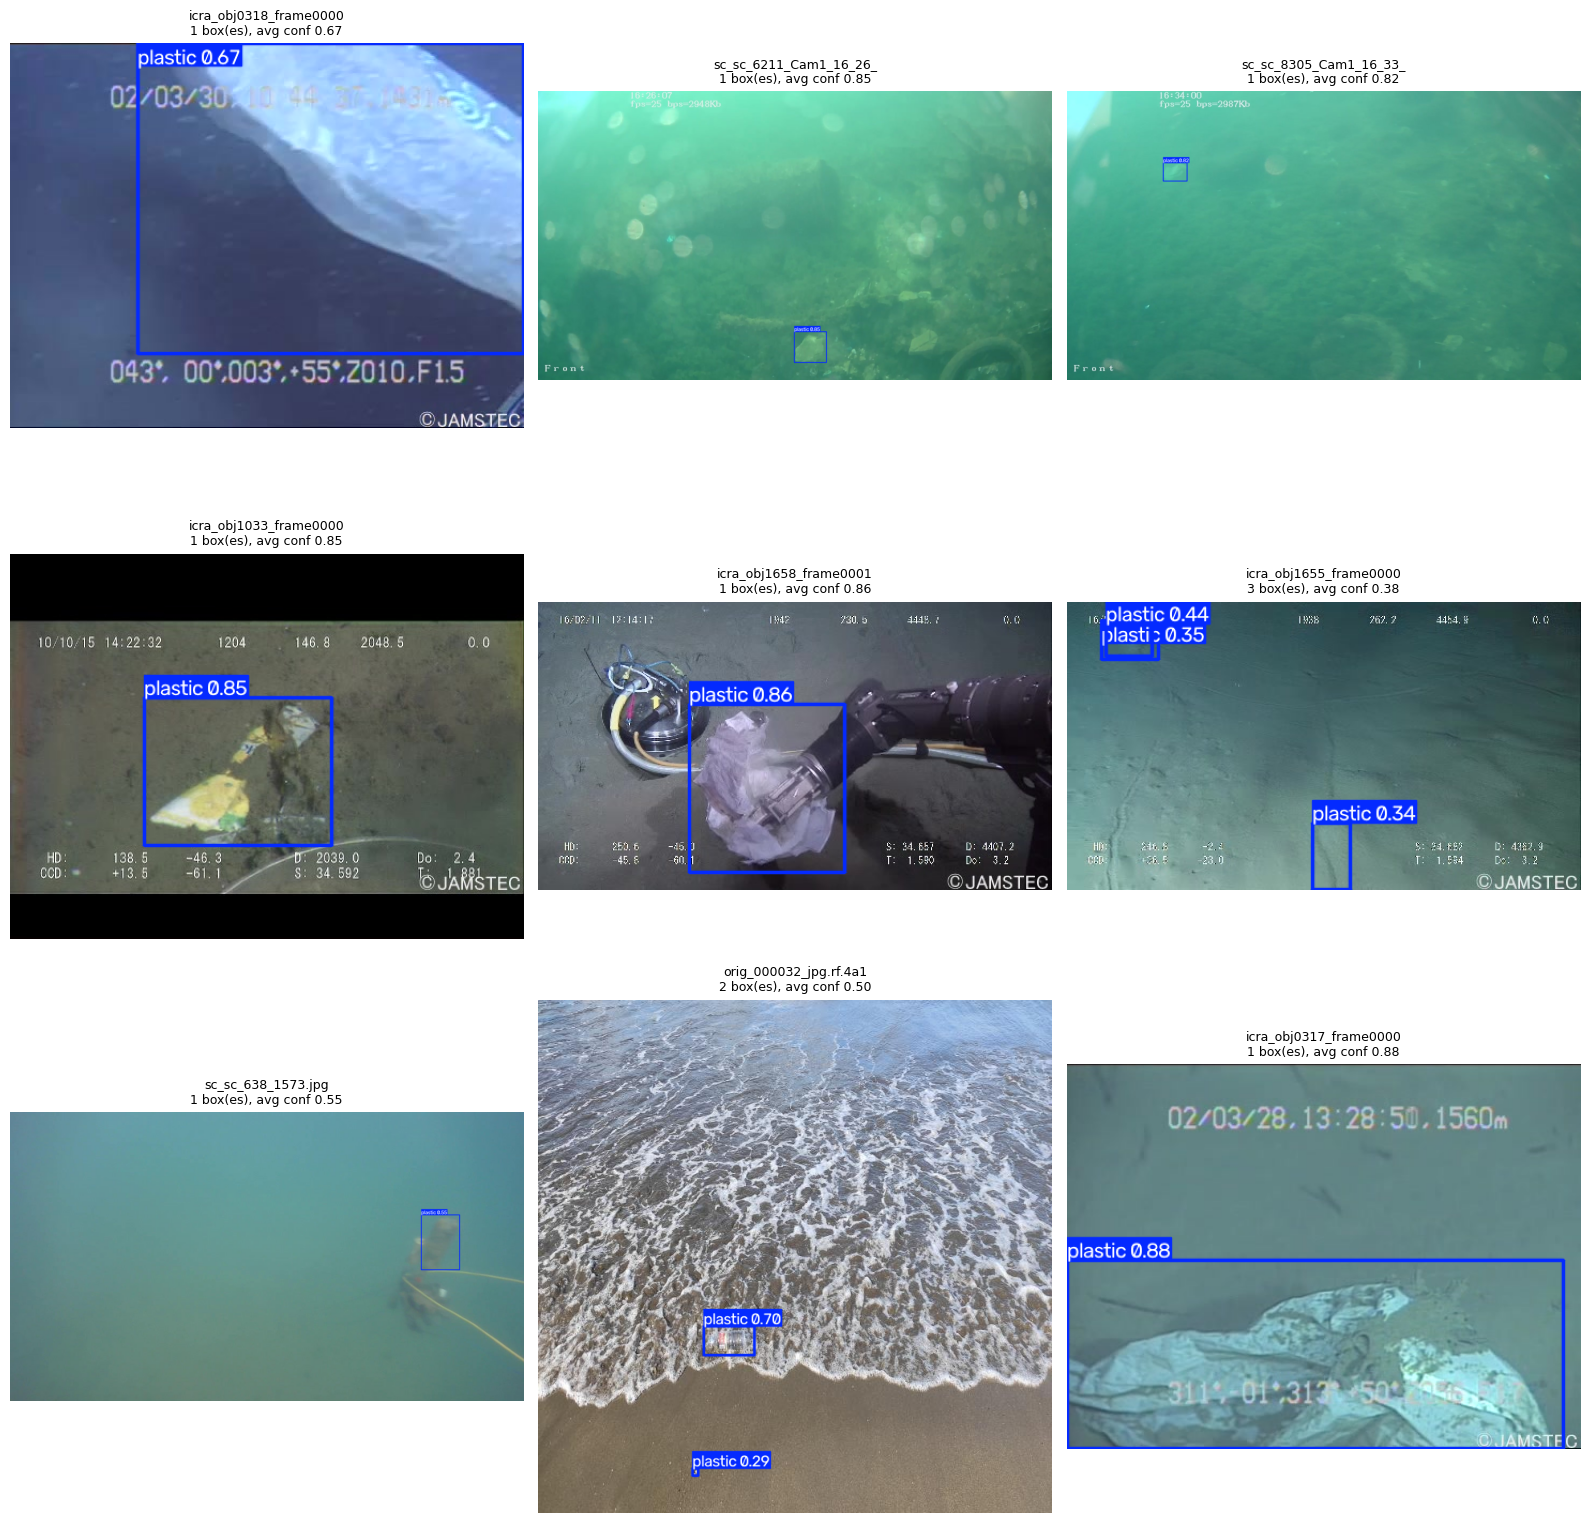


9 sample images shown | 0 with zero detections at conf>=0.25
Average confidence across all detected boxes: 0.633
Saved a copy to outputs_prediction_gallery.png (also grab this for your Phase-2 report screenshots).


In [23]:
N_SAMPLES = 9
CONF_THRESH = 0.25   # only draw boxes the model is at least this confident about

test_img_dir = os.path.join(MERGED_ROOT, "images", "test")
if not os.path.isdir(test_img_dir) or not os.listdir(test_img_dir):
    test_img_dir = os.path.join(MERGED_ROOT, "images", "val")

all_imgs = os.listdir(test_img_dir)
sample_imgs = random.sample(all_imgs, min(N_SAMPLES, len(all_imgs)))

n_cols = 3
n_rows = -(-len(sample_imgs) // n_cols)  # ceil
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5.3 * n_rows))
axes = axes.flatten() if len(sample_imgs) > 1 else [axes]

all_confidences = []
n_no_detections = 0

for ax, img_name in zip(axes, sample_imgs):
    img_path = os.path.join(test_img_dir, img_name)
    pred = best_model.predict(img_path, device=DEVICE, conf=CONF_THRESH, verbose=False)[0]

    annotated = pred.plot(line_width=2, font_size=1.0)  # draws boxes + class + confidence on the image
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))

    n_boxes = len(pred.boxes)
    if n_boxes == 0:
        n_no_detections += 1
        title = f"{img_name[:22]}\nNo detections >= {CONF_THRESH}"
    else:
        confs = pred.boxes.conf.tolist()
        all_confidences.extend(confs)
        title = f"{img_name[:22]}\n{n_boxes} box(es), avg conf {sum(confs)/len(confs):.2f}"
    ax.set_title(title, fontsize=9)
    ax.axis("off")

for ax in axes[len(sample_imgs):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("outputs_prediction_gallery.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n{len(sample_imgs)} sample images shown | "
      f"{n_no_detections} with zero detections at conf>={CONF_THRESH}")
if all_confidences:
    print(f"Average confidence across all detected boxes: {sum(all_confidences)/len(all_confidences):.3f}")
print("Saved a copy to outputs_prediction_gallery.png (also grab this for your Phase-2 report screenshots).")


## Step 7 — Overfit / Underfit Diagnostic (Automatic)

Reads the actual per-epoch train/val loss curves from `results.csv` and tells you, in plain terms, which regime the run landed in -- so if the number is below 70%, you know *why* instead of just re-running blind.


In [24]:
results_csv = os.path.join(RUN_DIR, "results.csv")
diag_df = pd.read_csv(results_csv)
diag_df.columns = [c.strip() for c in diag_df.columns]

train_loss_col = [c for c in diag_df.columns if "train/box_loss" in c][0]
val_loss_col = [c for c in diag_df.columns if "val/box_loss" in c][0]

final_train_loss = diag_df[train_loss_col].iloc[-1]
final_val_loss = diag_df[val_loss_col].iloc[-1]
min_val_loss = diag_df[val_loss_col].min()
min_val_epoch = int(diag_df[val_loss_col].idxmin()) + 1
last_epoch = len(diag_df)

print(f"Trained for {last_epoch} epochs.")
print(f"Final train box loss: {final_train_loss:.4f}")
print(f"Final val box loss:   {final_val_loss:.4f}")
print(f"Best val box loss:    {min_val_loss:.4f} (epoch {min_val_epoch})")
print()

gap = final_val_loss - final_train_loss
if min_val_epoch < last_epoch - max(5, int(0.15 * last_epoch)) and gap > 0.15:
    print("Diagnosis: likely OVERFITTING. Val loss stopped improving well before training ended "
          "and the train/val gap widened. Next time: fewer epochs (use the best-epoch checkpoint, "
          "which YOLO already saves as best.pt), more augmentation, or more data.")
elif min_val_epoch >= last_epoch - 2:
    print("Diagnosis: still IMPROVING when training stopped (underfitting slightly). "
          "Val loss was still going down at the final epoch. Next time: more epochs, or "
          "increase patience so early stopping doesn't cut it off early.")
else:
    print("Diagnosis: looks like a reasonably GOOD FIT. Val loss plateaued rather than "
          "diverging, and the best epoch isn't right at the very start or very end.")


Trained for 32 epochs.
Final train box loss: 1.0266
Final val box loss:   1.4354
Best val box loss:    1.4239 (epoch 27)

Diagnosis: looks like a reasonably GOOD FIT. Val loss plateaued rather than diverging, and the best epoch isn't right at the very start or very end.



results.png


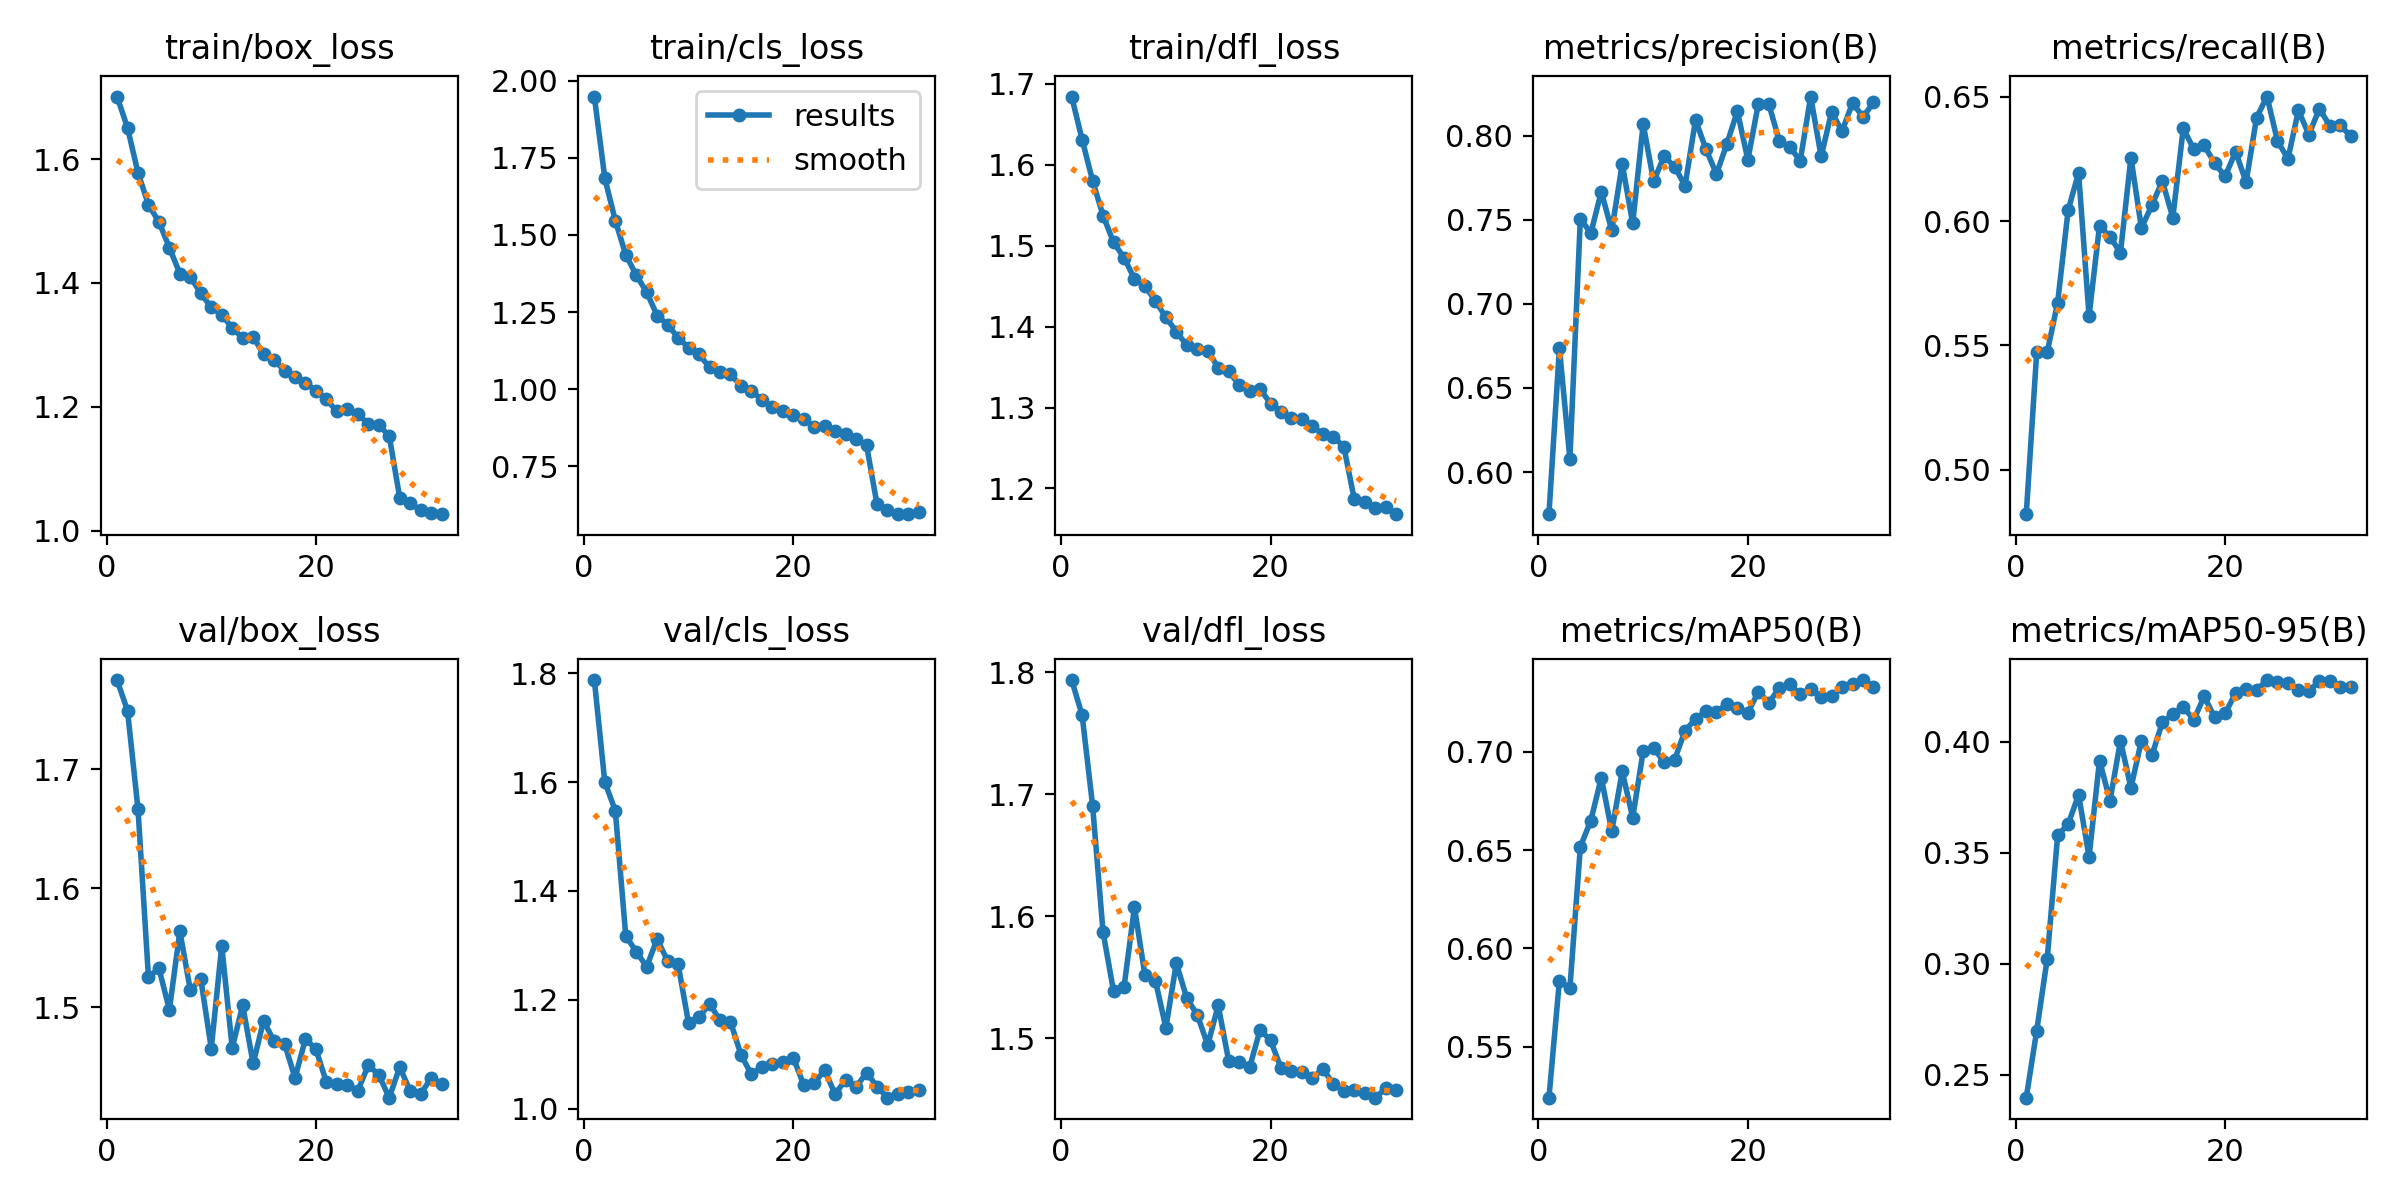


confusion_matrix.png


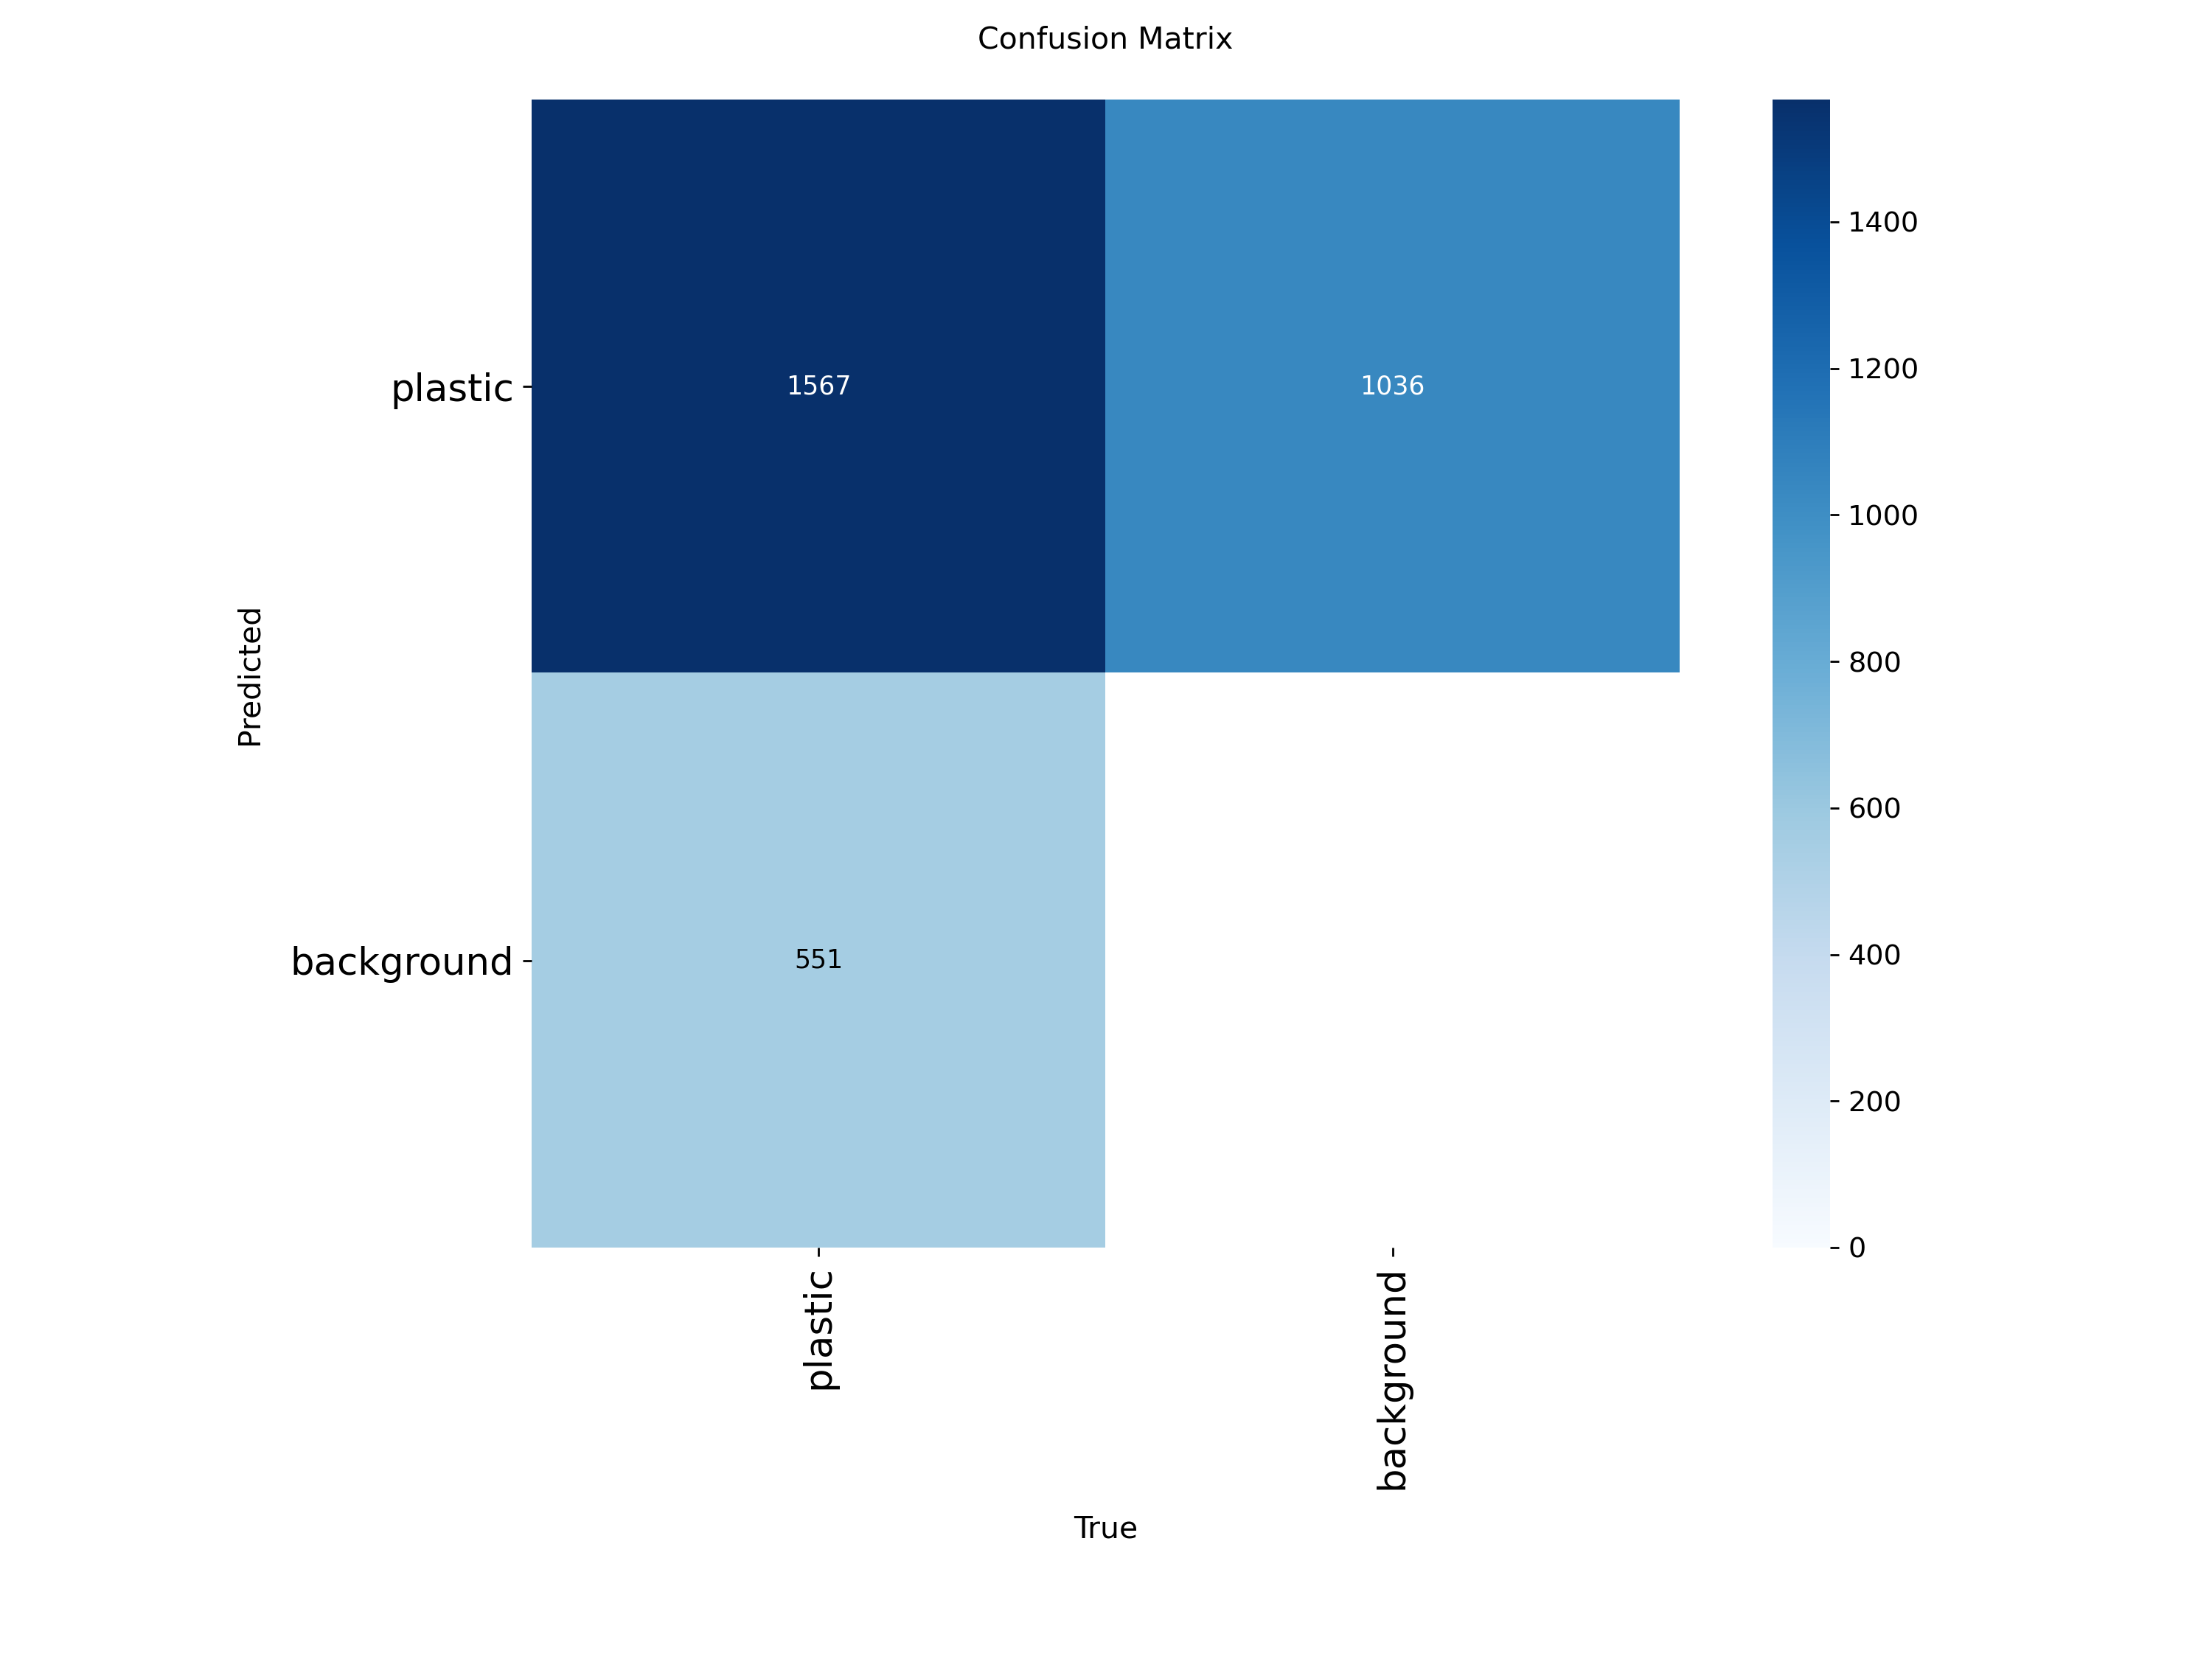

In [25]:
from IPython.display import Image, display
for fname in ["results.png", "confusion_matrix.png", "PR_curve.png", "F1_curve.png"]:
    fpath = os.path.join(RUN_DIR, fname)
    if os.path.exists(fpath):
        print(f"\n{fname}")
        display(Image(filename=fpath, width=650))


## Step 8 — Export Model

In [26]:
assert os.path.exists(best_model_path), "best.pt missing -- check Step 5 completed."
os.makedirs("outputs/models", exist_ok=True)
shutil.copy(best_model_path, "outputs/models/aqua_strat_best_v7.pt")
onnx_path = best_model.export(format="onnx", imgsz=IMGSZ)
shutil.copy(onnx_path, "outputs/models/aqua_strat_best_v7.onnx")
print("Exported to outputs/models/")

if IN_COLAB:
    from google.colab import files
    files.download("outputs/models/aqua_strat_best_v7.pt")


Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from 'runs/detect/runs/detect/aqua_strat_train_v8_4datasets_70min/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (49.6 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 298ms
Prepared 4 packages in 1.84s
Installed 4 packages in 271ms
 + colorama==0.4.6
 + onnx==1.22.0
 + onnxruntime==1.28.0
 + onnxslim==0.1.95

requirements: AutoUpdate success ✅ 3.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 20...
ONNX: slimming with onnxslim 0.1.95...
ONNX: export success ✅ 7.5

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary

| | v1 | v3 | v4 | v6 | v8 (this notebook) |
|---|---|---|---|---|---|
| Marine datasets | your 753 only | your 753 + OceanCV (noisy) | your 753 + TrashCan-plastic | + Trash-ICRA19-plastic | + **TrashCan-plastic + Trash-ICRA19-plastic + SeaClear-plastic** |
| API key needed | none | none | Kaggle (one-time) | Kaggle (reused) | Kaggle (reused) |
| Model | yolov8s | yolov8m | yolov8m | yolov8m | yolov8m |
| Resolution | 640 | 1024 | 1024 | 736 | 640 |
| Epochs | - | - | 80 | 40 (patience=12) | 32 (patience=10) |
| Backbone frozen | no | no | no | first 10 layers | first 14 layers |
| Prediction gallery | no | no | no | basic (6 img) | Step 6.5: 9 img, confidence shown, saved as PNG |
| Wall-clock (free T4) | - | - | ~4.5 hrs | ~60-75 min | target ~70 min |

**Important:** Run Steps 2, 2.5, and 2.75, then Step 4 and Step 4.5. Check that all four sources show non-zero image counts before starting Step 5.
